<a href="https://colab.research.google.com/github/emilianomtz0189/pld-monitoreo-transaccional/blob/main/notebooks/04_modelo_priorizacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/emilianomtz0189/pld-monitoreo-transaccional/blob/main/notebooks/04_modelo_priorizacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 · Modelo de priorización de alertas

**El problema (etapa 2):** las reglas generan cientos de alertas al día y la gran mayoría son falsos positivos. Revisarlas todas en el orden en que llegan no es viable.

**La solución:** un modelo que da a cada caso alertado una **probabilidad de ser sospechoso**, para que el equipo revise **primero** los más riesgosos. El modelo no reemplaza las reglas ni al analista: **ordena la fila de trabajo**.

**Reglas del juego (para que el resultado sea creíble):**
- **Unidad:** un **caso** = cuenta + semana con al menos una alerta. Así trabaja el analista.
- **Sin ver el futuro:** las variables usan solo información de esa semana y de semanas **anteriores**.
- **Validación temporal:** se entrena con los meses **anteriores** y se evalúa con los **posteriores**, como en producción.
- **Sin fuga de información:** no se usa la etiqueta ni la tipología como variable.
- **Etiqueta:** el caso es sospechoso si la cuenta envió o recibió alguna transacción sospechosa en esa semana.

**Métricas:**
- **PR-AUC:** qué tan bien ordena el modelo cuando los casos sospechosos son pocos. Un orden al azar obtiene la tasa base.
- **Recall en el top-K:** si solo se revisa el 10 %, 20 % o 30 % de los casos con mayor puntaje, ¿qué % de los sospechosos se encuentra?
- **Reducción de alertas:** cuántas alertas se dejan de revisar manteniendo el **90 %** de los casos sospechosos.

## 1. Entorno

In [1]:
import os
import sys
from pathlib import Path

USUARIO_GITHUB = "emilianomtz0189"
NOMBRE_REPO = "pld-monitoreo-transaccional"
CARPETA_DRIVE = Path("/content/drive/MyDrive/pld-monitoreo-transaccional")

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    ruta_repo = Path("/content") / NOMBRE_REPO
    if not ruta_repo.exists():
        !git clone -q https://github.com/{USUARIO_GITHUB}/{NOMBRE_REPO}.git {ruta_repo}
    else:
        !git -C {ruta_repo} pull -q
    os.chdir(ruta_repo)
else:
    CARPETA_DRIVE = None
    if Path.cwd().name == "notebooks":
        os.chdir("..")

sys.path.insert(0, str(Path.cwd()))
print("Directorio de trabajo:", Path.cwd())

Mounted at /content/drive
Directorio de trabajo: /content/pld-monitoreo-transaccional


In [2]:
!pip install -q -r requirements.txt

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer

from src import config, modelo, reglas
from src.datos import preparar_datos, recuperar_archivo, respaldar_resultados
from src.eda import (agregar_banderas, graficar_ganancia, graficar_importancia, graficar_pr,
                     guardar_figura, guardar_metricas)

config.fijar_semilla()
config.crear_carpetas()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
METRICAS = {}

## 2. Datos

In [4]:
df = preparar_datos(CARPETA_DRIVE)
df = agregar_banderas(df)
df = reglas.agregar_tiempo(df)

if not recuperar_archivo(config.ARCHIVO_ALERTAS, CARPETA_DRIVE):
    raise FileNotFoundError("No se encontró alertas.parquet: ejecuta primero el notebook 02_reglas_monitoreo.")
alertas = pd.read_parquet(config.ARCHIVO_ALERTAS)
print(f"Transacciones: {len(df):,} | Alertas de la etapa 2: {len(alertas):,} | Casos (cuenta + semana): {len(alertas.drop_duplicates(['cuenta', 'semana'])):,}")

Copiado desde Drive: /content/drive/MyDrive/pld-monitoreo-transaccional/transacciones.parquet
Transacciones: 9,504,852 | Alertas de la etapa 2: 249,869 | Casos (cuenta + semana): 230,508


## 3. Casos y variables

Cada caso recibe tres tipos de variables:
- **Reglas:** qué reglas lo alertaron (1/0), cuántas y cuántas transacciones marcaron.
- **Actividad de la semana:** como emisora y como receptora: número de operaciones, monto total y máximo, % en efectivo, % internacional y contrapartes distintas.
- **Comparación con su historia:** promedio semanal previo de la cuenta y cuántas veces lo supera esta semana; casos previos de la misma cuenta.

⏱️ Puede tardar 1 a 3 minutos.

In [5]:
casos = modelo.construir_casos(alertas)
casos = modelo.construir_variables(df, casos)
casos["y"] = modelo.etiquetar_casos(df, casos)

VARIABLES = [col for col in casos.columns if col not in ("cuenta", "semana", "y")]
print(f"Casos: {len(casos):,} | Sospechosos: {casos['y'].sum():,} ({100 * casos['y'].mean():.2f}%) | Variables: {len(VARIABLES)}")
pd.Series(VARIABLES, name="variable").to_frame()

Casos: 230,508 | Sospechosos: 3,213 (1.39%) | Variables: 33


,variable
0,regla_R1
1,regla_R2a
2,regla_R2b
3,regla_R3a
4,regla_R3b
5,regla_R4
6,regla_R5
7,regla_R6
8,num_reglas
9,transacciones_alertadas


## 4. Separación temporal

Se entrena con las primeras 30 semanas y se evalúa con las siguientes. El modelo nunca ve los meses de prueba al entrenar, igual que en producción, donde un modelo entrenado con el pasado se usa con casos futuros.

In [6]:
SEMANA_CORTE = 30
inicio = df["fecha_hora"].min().normalize()
fecha_corte = inicio + pd.Timedelta(days=7 * SEMANA_CORTE)

entrena = casos[casos["semana"] < SEMANA_CORTE]
prueba = casos[casos["semana"] >= SEMANA_CORTE]
dias_prueba = int(df.loc[df["semana"] >= SEMANA_CORTE, "dia"].nunique())

particion = pd.DataFrame({
    "desde": [inicio.date(), fecha_corte.date()],
    "hasta": [(fecha_corte - pd.Timedelta(days=1)).date(), df["fecha_hora"].max().date()],
    "casos": [len(entrena), len(prueba)],
    "sospechosos": [int(entrena["y"].sum()), int(prueba["y"].sum())],
    "tasa_pct": [round(100 * entrena["y"].mean(), 2), round(100 * prueba["y"].mean(), 2)],
}, index=["entrenamiento", "prueba"])
METRICAS["particion"] = particion.astype(str).reset_index().to_dict("records")
particion

,desde,hasta,casos,sospechosos,tasa_pct
entrenamiento,2022-10-07,2023-05-04,156167,1987,1.27
prueba,2023-05-05,2023-08-23,74341,1226,1.65


## 5. Modelos

- **Sin modelo (referencia):** ordenar por número de reglas que alertaron el caso. Es lo que haría un equipo sin modelo.
- **Regresión logística:** modelo lineal y explicable, como el scorecard de crédito. Los montos se transforman con logaritmo (tienen valores extremos) y se estandarizan.
- **LightGBM:** árboles de decisión potenciados. Captura combinaciones de variables y maneja faltantes, a cambio de ser menos transparente.

In [7]:
X_ent, y_ent = entrena[VARIABLES], entrena["y"].to_numpy()
X_pru, y_pru = prueba[VARIABLES], prueba["y"].to_numpy()

log_con_signo = FunctionTransformer(lambda X: np.sign(X) * np.log1p(np.abs(X)))
logistica = make_pipeline(SimpleImputer(strategy="median"), log_con_signo, StandardScaler(),
                          LogisticRegression(class_weight="balanced", max_iter=2000, random_state=config.SEMILLA))
logistica.fit(X_ent, y_ent)

lgbm = LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=50,
                      subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                      random_state=config.SEMILLA, verbose=-1)
lgbm.fit(X_ent, y_ent)

rng = np.random.default_rng(config.SEMILLA)
puntajes = {
    "LightGBM": lgbm.predict_proba(X_pru)[:, 1],
    "Regresión logística": logistica.predict_proba(X_pru)[:, 1],
    "Número de reglas (sin modelo)": X_pru["num_reglas"].to_numpy() + 1e-6 * rng.random(len(X_pru)),
}
print("Modelos entrenados.")

Modelos entrenados.


## 6. Resultados en la muestra de prueba

In [8]:
resultados = pd.DataFrame({nombre: modelo.metricas_priorizacion(y_pru, p) for nombre, p in puntajes.items()}).T
METRICAS["resultados_prueba"] = resultados.reset_index(names="metodo").to_dict("records")
resultados

,casos,casos_sospechosos,tasa_base_pct,pr_auc,recall_top_10pct,precision_top_10pct,recall_top_20pct,precision_top_20pct,recall_top_30pct,precision_top_30pct,alertas_para_90pct_recall,pct_alertas_para_90pct_recall,reduccion_de_alertas_pct
LightGBM,74341.0,1226.0,1.65,0.6271,83.52,13.77,93.15,7.68,97.47,5.36,12234.0,16.46,83.54
Regresión logística,74341.0,1226.0,1.65,0.1546,49.84,8.22,71.62,5.91,81.57,4.48,32591.0,43.84,56.16
Número de reglas (sin modelo),74341.0,1226.0,1.65,0.0207,17.94,2.96,26.18,2.16,35.48,1.95,66582.0,89.56,10.44


Gráfica guardada: resultados/figuras/12_curva_ganancia.png


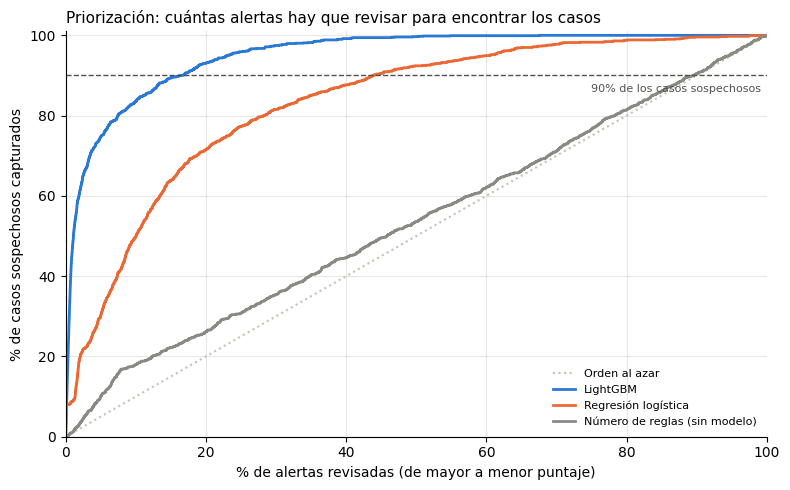

In [9]:
fig = graficar_ganancia({n: modelo.curva_ganancia(y_pru, p) for n, p in puntajes.items()})
guardar_figura(fig, "12_curva_ganancia.png")
plt.show()

Gráfica guardada: resultados/figuras/13_curva_precision_recall.png


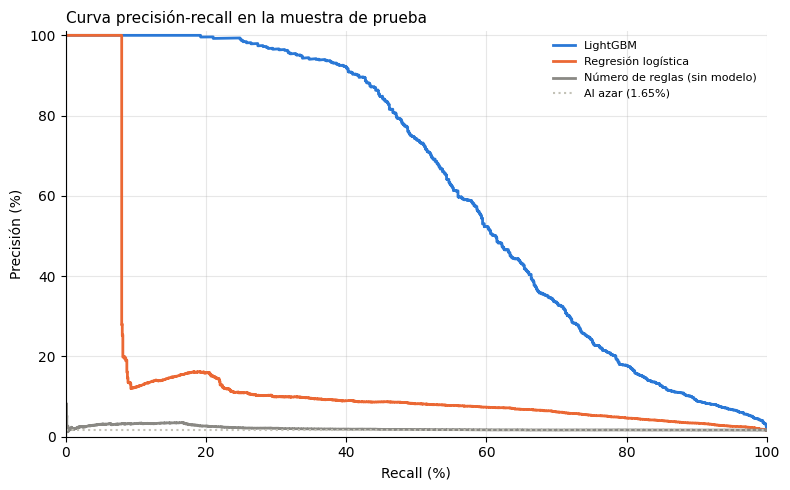

In [10]:
fig = graficar_pr({n: modelo.curva_pr(y_pru, p) for n, p in puntajes.items()}, tasa_base=100 * y_pru.mean())
guardar_figura(fig, "13_curva_precision_recall.png")
plt.show()

### Traducción a carga de trabajo
Cuántas alertas al día habría que revisar en el periodo de prueba: todas, o solo las necesarias para encontrar el 90 % de los casos sospechosos, en el orden de cada método.

In [11]:
carga = pd.DataFrame({
    "alertas_por_dia_revisando_todo": len(prueba) / dias_prueba,
    "alertas_por_dia_para_90pct": resultados["alertas_para_90pct_recall"].astype(float) / dias_prueba,
    "reduccion_de_alertas_pct": resultados["reduccion_de_alertas_pct"].astype(float),
}).round(1)
METRICAS["dias_prueba"] = dias_prueba
METRICAS["carga_trabajo"] = carga.reset_index(names="metodo").to_dict("records")
carga

,alertas_por_dia_revisando_todo,alertas_por_dia_para_90pct,reduccion_de_alertas_pct
LightGBM,669.7,110.2,83.5
Regresión logística,669.7,293.6,56.2
Número de reglas (sin modelo),669.7,599.8,10.4


## 7. ¿Qué variables usa el modelo?

Para un área de cumplimiento no basta con que el modelo funcione: debe poder **explicarse** al comité, a auditoría y al supervisor.

Gráfica guardada: resultados/figuras/14_importancia_lightgbm.png


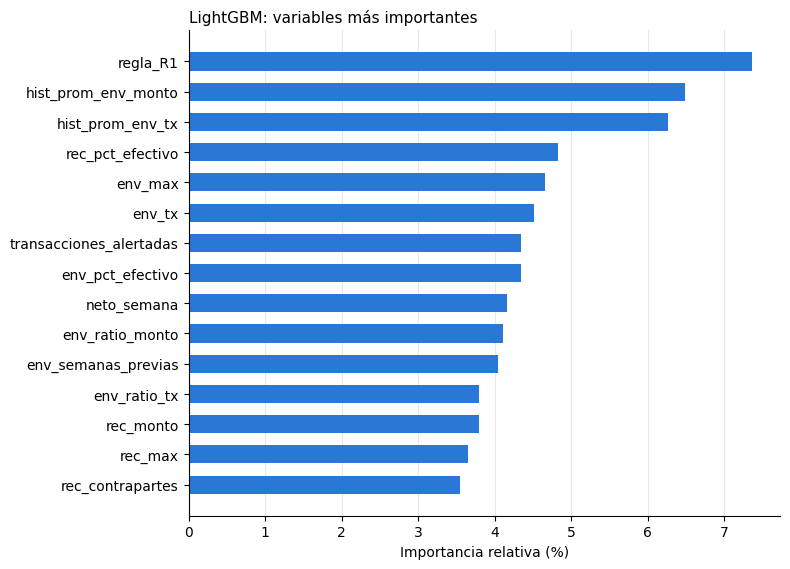

In [12]:
imp_lgbm = pd.Series(lgbm.booster_.feature_importance(importance_type="gain"), index=VARIABLES)
imp_lgbm = (100 * imp_lgbm / imp_lgbm.sum()).sort_values(ascending=False).head(15).round(2)
METRICAS["importancia_lightgbm"] = imp_lgbm.to_dict()
fig = graficar_importancia(imp_lgbm, "LightGBM: variables más importantes")
guardar_figura(fig, "14_importancia_lightgbm.png")
plt.show()

In [13]:
# Regresión logística: coeficiente de cada variable (estandarizada). Positivo = sube el riesgo.
coef = pd.Series(logistica[-1].coef_[0], index=VARIABLES).sort_values(key=abs, ascending=False).head(15).round(3)
METRICAS["coeficientes_logistica"] = coef.to_dict()
coef.to_frame("coeficiente")

,coeficiente
env_tx,-2.886
rec_contrapartes,1.428
rec_tx,-1.377
env_ratio_tx,1.275
env_contrapartes,1.151
rec_monto,1.101
regla_R1,1.042
env_monto,0.978
env_max,-0.847
regla_R3b,-0.735


## 8. Guardado

In [14]:
METRICAS["semana_corte"] = SEMANA_CORTE
METRICAS["fecha_corte"] = str(fecha_corte.date())
METRICAS["variables"] = VARIABLES
guardar_metricas(METRICAS, "04_modelo.json")
if CARPETA_DRIVE is not None:
    respaldar_resultados(CARPETA_DRIVE)

mejor = resultados["pr_auc"].astype(float).idxmax()
r, ref = resultados.loc[mejor], resultados.loc["Número de reglas (sin modelo)"]
print(f'''
RESUMEN ETAPA 4
- Prueba: {int(r["casos"]):,} casos, {int(r["casos_sospechosos"]):,} sospechosos (tasa base {r["tasa_base_pct"]}%).
- Mejor modelo: {mejor} | PR-AUC {r["pr_auc"]} (sin modelo: {ref["pr_auc"]}).
- Revisando el 10% de casos con mayor puntaje se encuentra el {r["recall_top_10pct"]}% de los sospechosos.
- Para encontrar el 90% basta revisar el {r["pct_alertas_para_90pct_recall"]}% de las alertas: reducción de {r["reduccion_de_alertas_pct"]}% (sin modelo: {ref["reduccion_de_alertas_pct"]}%).
- Carga: de {carga.loc[mejor, "alertas_por_dia_revisando_todo"]} a {carga.loc[mejor, "alertas_por_dia_para_90pct"]} alertas por día.
''')

Métricas guardadas: resultados/metricas/04_modelo.json
Resultados respaldados en /content/drive/MyDrive/pld-monitoreo-transaccional/resultados

RESUMEN ETAPA 4
- Prueba: 74,341 casos, 1,226 sospechosos (tasa base 1.65%).
- Mejor modelo: LightGBM | PR-AUC 0.6271 (sin modelo: 0.0207).
- Revisando el 10% de casos con mayor puntaje se encuentra el 83.52% de los sospechosos.
- Para encontrar el 90% basta revisar el 16.46% de las alertas: reducción de 83.54% (sin modelo: 10.44%).
- Carga: de 669.7 a 110.2 alertas por día.



**Siguiente paso:** etapa 5, resultados y README final.